# Линейное программирование


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
import datetime
import pyomo.environ as pyo

In [1]:
# HiGHS — решатель, который будет находить оптимальное решение.

# Общая функция для запуска решателя и проверки статуса решения.
def solve_model(model, название="модель"):
    # Создаем решатель HiGHS. Он поддерживает линейные задачи.
    solver = pyo.SolverFactory("appsi_highs")
    result = solver.solve(model)

    # Проверяем, что решатель нашел оптимальное решение.
    status = result.solver.termination_condition
    print(f"Результат для: {название}")
    print("Статус решателя:", status)

    if status != pyo.TerminationCondition.optimal:
        print("Оптимальное решение не найдено. Проверьте данные и ограничения.")
        return result

    return result


In [5]:
solver = pyo.SolverFactory("appsi_highs")
print("Решатель доступен:", solver.available())

Решатель доступен: True


## 2.1

Менеджер магазина смартфонов стремится реализовать имеющиеся запасы в связи с появлением новых моделей. В наличии имеется 8 телефонов, 4 комплекта гарнитур и 19 предоплаченных карт. Согласно результатам маркетингового исследования, менеджер может сформировать два вида комплектов:
 * комплект из телефона и двух предоплаченных карт, приносящий прибыль $7
 
 * комплект из телефона, гарнитуры и трёх предоплаченных карт, приносящий прибыль $9.

Предполагается, что любое количество комплектов обоих видов может быть реализовано при условии наличия соответствующих товаров

(a) Сформулируйте задачу линейного программирования, определяющую количество комплектов каждого вида, которое следует подготовить для максимизации прибыли. Найдите оптимальное решение.

(b) Торговый представитель сети супермаркетов предлагает выкупить товарные запасы магазина по отдельным позициям, а не сформированными комплектами. Определите минимальные удельные цены на телефон, гарнитуру и предоплаченную карту, которые обеспечили бы менеджеру не меньшую прибыль, чем самостоятельная реализация комплектов.

(c) Какова взаимосвязь между моделями, построенными в пунктах (a) и (b)?

(d) Как следует оценить предложение супермаркета о выкупе всего товарного
запаса по цене:
* $65;

* $62;

* $60?

In [6]:
# Пункт (a) - максимизация выгоды
m21a = pyo.ConcreteModel()

# х1 - Число комплектов "телефон + 2 карты"
m21a.x1 = pyo.Var(domain=pyo.NonNegativeReals)
# х2 - Число комплектов "телефон + гарнитура + 3 карты"
m21a.x2 = pyo.Var(domain=pyo.NonNegativeReals)

# Целевая функция: общая прибыль. 7 - прибыль х1, 9 - прибыль х2
m21a.profit = pyo.Objective(expr=7*m21a.x1 + 9*m21a.x2, sense=pyo.maximize)

# Ограничения по запасам (8 телефонов, 4 комплекта гарнитур и 19 предоплаченных карт)
m21a.phones = pyo.Constraint(expr=m21a.x1 + m21a.x2 <= 8)
m21a.headsets = pyo.Constraint(expr=m21a.x2 <= 4)
m21a.cards = pyo.Constraint(expr=2*m21a.x1 + 3*m21a.x2 <= 19)

# Вызов функции
solve_model(m21a, "2.1(a)")
print("Комплектов первого типа:", pyo.value(m21a.x1))
print("Комплектов второго типа:", pyo.value(m21a.x2))
print("Максимальная прибыль: $", pyo.value(m21a.profit))


Результат для: 2.1(a)
Статус решателя: optimal
Комплектов первого типа: 5.0
Комплектов второго типа: 3.0
Максимальная прибыль: $ 62.0


In [7]:
# Пункт (b): минимальные удельные цены.
m21b = pyo.ConcreteModel()

# Неотрицательные оценки (цены) единицы каждого ресурса.
m21b.p_phone = pyo.Var(domain=pyo.NonNegativeReals)
m21b.p_headset = pyo.Var(domain=pyo.NonNegativeReals)
m21b.p_card = pyo.Var(domain=pyo.NonNegativeReals)

# Минимизируем общую стоимость всего запаса при этих оценках.
m21b.cost = pyo.Objective(
    expr=8*m21b.p_phone + 4*m21b.p_headset + 19*m21b.p_card,
    sense=pyo.minimize
)

# Оценка товаров, входящих в каждый комплект, должна покрывать его прибыль.
m21b.bundle1 = pyo.Constraint(expr=m21b.p_phone + 2*m21b.p_card >= 7)
m21b.bundle2 = pyo.Constraint(
    expr=m21b.p_phone + m21b.p_headset + 3*m21b.p_card >= 9
)

solve_model(m21b, "2.1(b)")
print("Цена телефона: $", pyo.value(m21b.p_phone))
print("Цена гарнитуры: $", pyo.value(m21b.p_headset))
print("Цена карты: $", pyo.value(m21b.p_card))
print("Оценка всего запаса по двойственной задаче: $", pyo.value(m21b.cost))


Результат для: 2.1(b)
Статус решателя: optimal
Цена телефона: $ 3.0
Цена гарнитуры: $ 0.0
Цена карты: $ 2.0
Оценка всего запаса по двойственной задаче: $ 62.0


(c). Связь двух моделей
Задачи из пунктов (a) и (b) — прямая и двойственная задачи линейного программирования.
- Прямая задача выбирает количество комплектов для максимизации прибыли.
- Двойственная задача определяет оценки ресурсов, минимизирующие стоимость запасов при условии, что стоимость каждого комплекта покрывает его прибыль.
В этом примере оптимальные значения совпали.

Это иллюстрирует теорему сильной двойственности: если прямая и двойственная задачи имеют оптимальные решения, их оптимальные значения совпадают.

(d). Оценка предложения супермаркета
Сравниваем цену выкупа всего запаса с оптимальной прибылью $62.

Вывод: менеджеру выгодно принять предложение на $65, принять предложение на $62 можно без потери прибыли, а предложение на $60 уступает самостоятельной реализации комплектов.

In [8]:
# Пункт (d): исходная задача — предложение о выкупе.
# Автоматически сравниваем предложения $65, $62 и $60
best_profit_21 = pyo.value(m21a.profit)

for offer in [65, 62, 60]:
    print(f"Предложение ${offer}: ", end="")
    if offer > best_profit_21:
        print("выгоднее продать весь запас супермаркету.")
    elif offer < best_profit_21:
        print("выгоднее самостоятельно собирать комплекты.")
    else:
        print("по прибыли оба варианта равноценны.")


Предложение $65: выгоднее продать весь запас супермаркету.
Предложение $62: по прибыли оба варианта равноценны.
Предложение $60: выгоднее самостоятельно собирать комплекты.


## 2.2

Компания Furnco производит столы и стулья, используя древесину и трудовые ресурсы. Стоимость древесины составляет $1 за досковый фут, а её доступный объём равен 40 000 досковых футов. На один стол требуется 40 досковых футов древесины, на один стул — 30. Изготовление незавершённого стола или стула требует 2 часов труда; для их отделки необходимо дополнительно соответственно 3 и 2 часа. Общий фонд рабочего времени составляет 6000 часов (уже оплачен).
Незавершённые и готовые столы продаются соответственно по $70 и $140, а стулья по $60 и $110. Сформулируйте задачу линейного программирования для максимизации прибыли от производства столов и стульев.

In [1]:
m22 = pyo.ConcreteModel()

# Количество изделий каждого типа (непрерывные переменные — задача ЛП).
m22.table_unfinished = pyo.Var(domain=pyo.NonNegativeReals)
m22.table_finished = pyo.Var(domain=pyo.NonNegativeReals)
m22.chair_unfinished = pyo.Var(domain=pyo.NonNegativeReals)
m22.chair_finished = pyo.Var(domain=pyo.NonNegativeReals)

# Прибыль = цена продажи - стоимость древесины ($1 за досковый фут).
# Стол использует 40 футов, стул — 30.
# Незавершенный стол: 70 - 40; готовый стол: 140 - 40.
# Незавершенный стул: 60 - 30; готовый стул: 110 - 30.
# Труд уже оплачен, поэтому из прибыли его не вычитаем.
m22.profit = pyo.Objective(
    expr=30*m22.table_unfinished + 100*m22.table_finished
       + 30*m22.chair_unfinished + 80*m22.chair_finished,
    sense=pyo.maximize
)

# Ограничение по древесине: и незавершенное, и готовое изделие используют древесину.
m22.wood = pyo.Constraint(
    expr=40*(m22.table_unfinished + m22.table_finished)
       + 30*(m22.chair_unfinished + m22.chair_finished) <= 40000
)

# Труд: на каждое изделие требуется 2 часа изготовления.
# На отделку дополнительно нужно 3 часа для стола и 2 часа для стула.
m22.labor = pyo.Constraint(
    expr=2*m22.table_unfinished + 5*m22.table_finished
       + 2*m22.chair_unfinished + 4*m22.chair_finished <= 6000
)

solve_model(m22, "2.2")
print("Незавершённых столов:", pyo.value(m22.table_unfinished))
print("Готовых столов:", pyo.value(m22.table_finished))
print("Незавершённых стульев:", pyo.value(m22.chair_unfinished))
print("Готовых стульев:", pyo.value(m22.chair_finished))
print("Максимальная прибыль после оплаты древесины: $", pyo.value(m22.profit))


Результат для: 2.2
Статус решателя: optimal
Незавершённых столов: 0.0
Готовых столов: 0.0
Незавершённых стульев: 0.0
Готовых стульев: 1333.3333333333321
Максимальная прибыль после оплаты древесины: $ 106666.66666666657


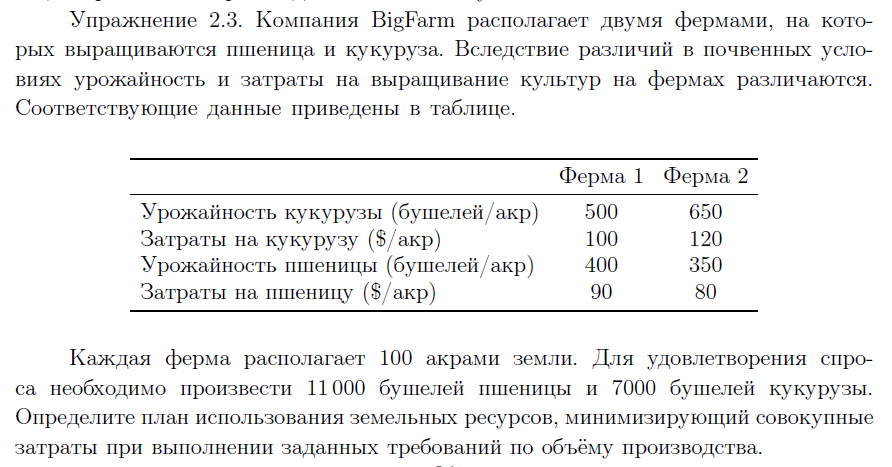

In [10]:
m23 = pyo.ConcreteModel()

# Площади под культуры: ферма 1 и ферма 2.
m23.corn1 = pyo.Var(domain=pyo.NonNegativeReals)
m23.corn2 = pyo.Var(domain=pyo.NonNegativeReals)
m23.wheat1 = pyo.Var(domain=pyo.NonNegativeReals)
m23.wheat2 = pyo.Var(domain=pyo.NonNegativeReals)

# Затраты на акр: кукуруза $100/$120, пшеница $90/$80.
m23.cost = pyo.Objective(
    expr=100*m23.corn1 + 120*m23.corn2
       + 90*m23.wheat1 + 80*m23.wheat2,
    sense=pyo.minimize
)

m23.land1 = pyo.Constraint(expr=m23.corn1 + m23.wheat1 <= 100)
m23.land2 = pyo.Constraint(expr=m23.corn2 + m23.wheat2 <= 100)

# Минимальные объемы производства.
m23.corn_demand = pyo.Constraint(expr=500*m23.corn1 + 650*m23.corn2 >= 7000)
m23.wheat_demand = pyo.Constraint(expr=400*m23.wheat1 + 350*m23.wheat2 >= 11000)

solve_model(m23, "2.3")
for name in ["corn1", "corn2", "wheat1", "wheat2"]:
    print(name, "=", pyo.value(getattr(m23, name)), "акров")
print("Минимальные затраты: $", pyo.value(m23.cost))


Результат для: 2.3
Статус решателя: optimal
corn1 = 0.0 акров
corn2 = 10.76923076923077 акров
wheat1 = 27.5 акров
wheat2 = 0.0 акров
Минимальные затраты: $ 3767.3076923076924


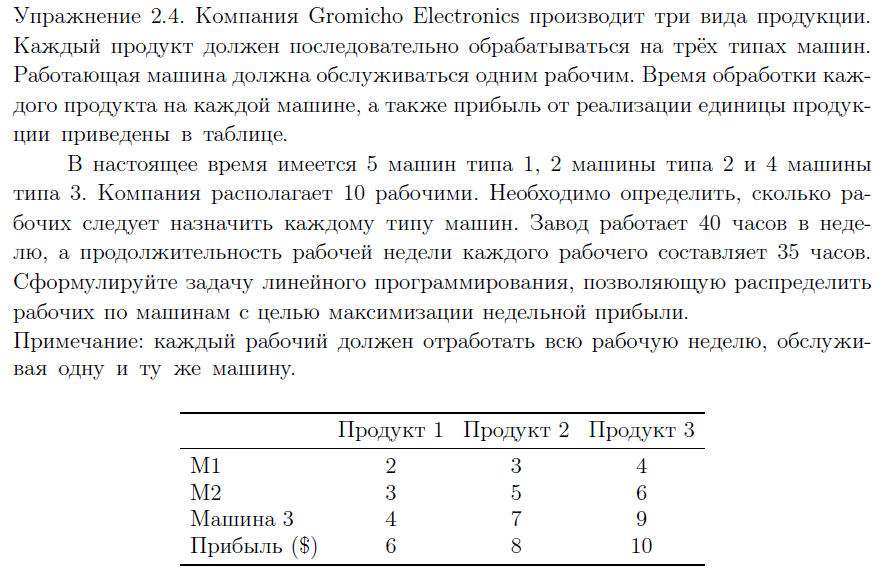

In [1]:
m24 = pyo.ConcreteModel()

# Количество единиц каждого продукта за неделю.
m24.x1 = pyo.Var(domain=pyo.NonNegativeReals)
m24.x2 = pyo.Var(domain=pyo.NonNegativeReals)
m24.x3 = pyo.Var(domain=pyo.NonNegativeReals)

# Количество работников на каждом типе машин — целые числа.
m24.w1 = pyo.Var(domain=pyo.NonNegativeIntegers)
m24.w2 = pyo.Var(domain=pyo.NonNegativeIntegers)
m24.w3 = pyo.Var(domain=pyo.NonNegativeIntegers)

# Прибыль за единицу продукта: $6, $8, $10.
m24.profit = pyo.Objective(
    expr=6*m24.x1 + 8*m24.x2 + 10*m24.x3,
    sense=pyo.maximize
)

# На каждой машине одного типа не может работать больше одного человека.
# Доступно 5 машин M1, 2 машины M2 и 4 машины M3.
m24.machine1_workers = pyo.Constraint(expr=m24.w1 <= 5)
m24.machine2_workers = pyo.Constraint(expr=m24.w2 <= 2)
m24.machine3_workers = pyo.Constraint(expr=m24.w3 <= 4)

# Не более 10 работников (необязательно задействовать всех).
m24.total_workers = pyo.Constraint(expr=m24.w1 + m24.w2 + m24.w3 <= 10)

# Объем обработки не может превышать доступные часы работников (35 часов на человека).
m24.capacity1 = pyo.Constraint(expr=2*m24.x1 + 3*m24.x2 + 4*m24.x3 <= 35*m24.w1)
m24.capacity2 = pyo.Constraint(expr=3*m24.x1 + 5*m24.x2 + 6*m24.x3 <= 35*m24.w2)
m24.capacity3 = pyo.Constraint(expr=4*m24.x1 + 7*m24.x2 + 9*m24.x3 <= 35*m24.w3)

solve_model(m24, "2.4")
print("Работников на M1, M2, M3:", pyo.value(m24.w1), pyo.value(m24.w2), pyo.value(m24.w3))
print("Продукция 1, 2, 3:", pyo.value(m24.x1), pyo.value(m24.x2), pyo.value(m24.x3))
print("Максимальная недельная прибыль: $", pyo.value(m24.profit))


Результат для: 2.4
Статус решателя: optimal
Работников на M1, M2, M3: 2.0000000000000004 2.0 3.0
Продукция 1, 2, 3: 23.333333333333332 -0.0 0.0
Максимальная недельная прибыль: $ 140.0


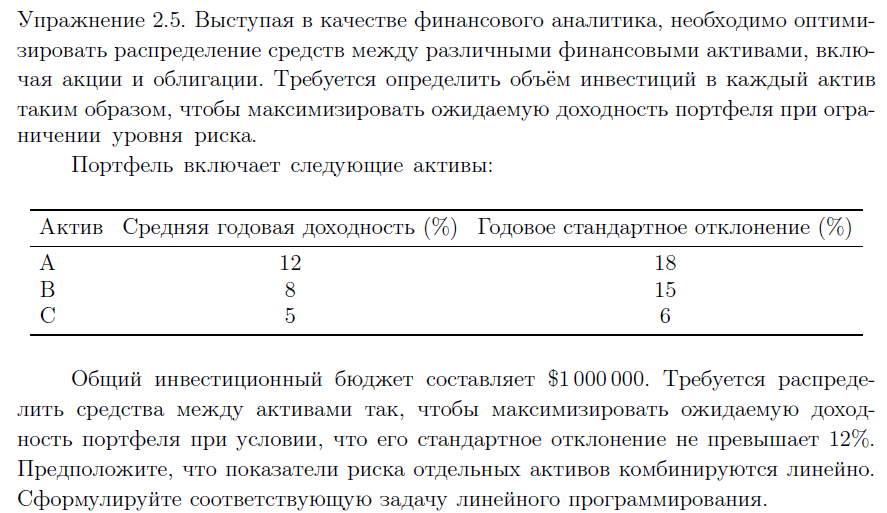

In [12]:
m25 = pyo.ConcreteModel()

# Суммы денег, вложенные в три актива: А, В, С
m25.A = pyo.Var(domain=pyo.NonNegativeReals)
m25.B = pyo.Var(domain=pyo.NonNegativeReals)
m25.C = pyo.Var(domain=pyo.NonNegativeReals)

# Максимизация ожидаемой доходности в долларах.
m25.return_value = pyo.Objective(
    expr=0.12*m25.A + 0.08*m25.B + 0.05*m25.C,
    sense=pyo.maximize
)

# Весь бюджет должен быть инвестирован.
m25.budget = pyo.Constraint(expr=m25.A + m25.B + m25.C == 1_000_000)

# Линейное ограничение риска: средневзвешенный риск не выше 12%.
# Умножаем риск каждого актива на сумму вложений в него.
m25.risk = pyo.Constraint(
    expr=0.18*m25.A + 0.15*m25.B + 0.06*m25.C <= 0.12*1_000_000
)

solve_model(m25, "2.5")
print("Вложение в A: $", pyo.value(m25.A))
print("Вложение в B: $", pyo.value(m25.B))
print("Вложение в C: $", pyo.value(m25.C))
print("Ожидаемая годовая доходность: $", pyo.value(m25.return_value))
print("Риск в пересчете на весь портфель: ", (0.18*pyo.value(m25.A)+0.15*pyo.value(m25.B)+0.06*pyo.value(m25.C))/1_000_000*100, "%")


Результат для: 2.5
Статус решателя: optimal
Вложение в A: $ 500000.0
Вложение в B: $ 0.0
Вложение в C: $ 500000.0
Ожидаемая годовая доходность: $ 85000.0
Риск в пересчете на весь портфель:  12.0 %


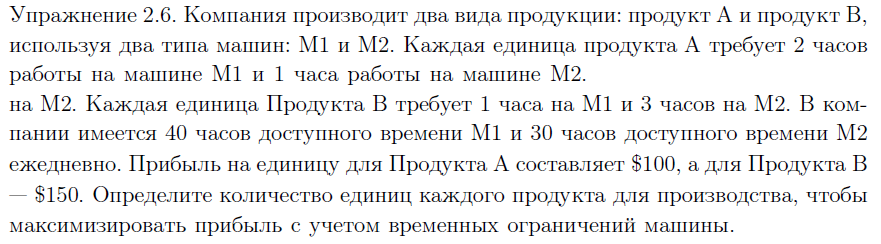

In [13]:
m26 = pyo.ConcreteModel()

# Объемы выпуска продуктов А и В
m26.xA = pyo.Var(domain=pyo.NonNegativeReals)
m26.xB = pyo.Var(domain=pyo.NonNegativeReals)

m26.profit = pyo.Objective(expr=100*m26.xA + 150*m26.xB, sense=pyo.maximize)

# M1: A требует 2 часа, B — 1 час; доступно 40 часов.
m26.M1 = pyo.Constraint(expr=2*m26.xA + m26.xB <= 40)

# M2: A требует 1 час, B — 3 часа; доступно 30 часов.
m26.M2 = pyo.Constraint(expr=m26.xA + 3*m26.xB <= 30)

solve_model(m26, "2.6")
print("Количество A:", pyo.value(m26.xA))
print("Количество B:", pyo.value(m26.xB))
print("Максимальная прибыль за день: $", pyo.value(m26.profit))


Результат для: 2.6
Статус решателя: optimal
Количество A: 18.0
Количество B: 4.0
Максимальная прибыль за день: $ 2400.0


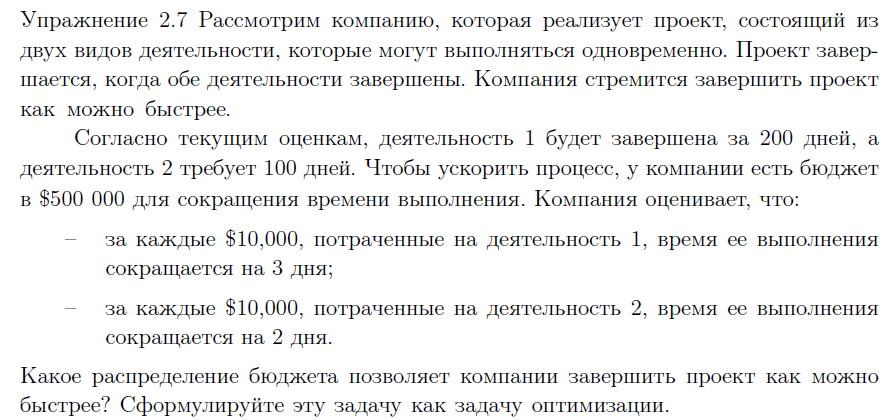

In [1]:
m27 = pyo.ConcreteModel()

# Расходы измеряются блоками по $10 000.
m27.u1 = pyo.Var(domain=pyo.NonNegativeReals)
m27.u2 = pyo.Var(domain=pyo.NonNegativeReals)
# Т - время завершения всего проекта
m27.T = pyo.Var(domain=pyo.NonNegativeReals)

# Минимизируем срок завершения всего проекта.
m27.objective = pyo.Objective(expr=m27.T, sense=pyo.minimize)

# $500 000 / $10 000 = 50 блоков бюджета.
m27.budget = pyo.Constraint(expr=m27.u1 + m27.u2 <= 50)

# На каждые $10 000 время активности 1 (200 дней) сокращается на 3 дня.
# T >= max(T1, T2), где Ti — длительности параллельных активностей.
m27.activity1 = pyo.Constraint(expr=m27.T >= 200 - 3*m27.u1)

# На каждые $10 000 время активности 2 (100 дней) сокращается на 2 дня.
m27.activity2 = pyo.Constraint(expr=m27.T >= 100 - 2*m27.u2)

# Длительности активностей не могут быть отрицательными.
m27.duration1_nonneg = pyo.Constraint(expr=200 - 3*m27.u1 >= 0)
m27.duration2_nonneg = pyo.Constraint(expr=100 - 2*m27.u2 >= 0)

solve_model(m27, "2.7")
print("Блоков по $10 000 на деятельность 1:", pyo.value(m27.u1))
print("Блоков по $10 000 на деятельность 2:", pyo.value(m27.u2))
print("Расход на деятельность 1: $", 10000*pyo.value(m27.u1))
print("Расход на деятельность 2: $", 10000*pyo.value(m27.u2))
print("Минимальная длительность проекта:", pyo.value(m27.T), "дней")


Результат для: 2.7
Статус решателя: optimal
Блоков по $10 000 на деятельность 1: 40.0
Блоков по $10 000 на деятельность 2: 10.0
Расход на деятельность 1: $ 400000.0
Расход на деятельность 2: $ 100000.0
Минимальная длительность проекта: 80.0 дней


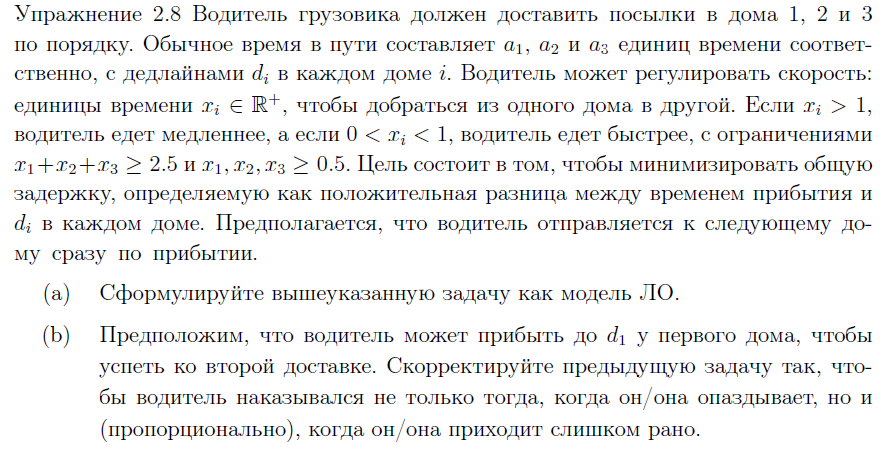

In [1]:
# Пункт (a). Символьная формулировка ЛП:
#   переменные: x_i >= 0.5, late_i >= 0
#   прибытие: T1 = a1*x1, T2 = a1*x1+a2*x2, T3 = a1*x1+a2*x2+a3*x3
#   min late1+late2+late3
#   s.t. x1+x2+x3 >= 2.5
#        late_i >= T_i - d_i
#
# Числовой пример с ненулевыми опозданиями (a_i, d_i — параметры задачи).
a1, a2, a3 = 2.0, 2.0, 2.0
d1, d2, d3 = 0.5, 1.5, 3.0

m28a = pyo.ConcreteModel()

m28a.x1 = pyo.Var(domain=pyo.NonNegativeReals)
m28a.x2 = pyo.Var(domain=pyo.NonNegativeReals)
m28a.x3 = pyo.Var(domain=pyo.NonNegativeReals)

m28a.late1 = pyo.Var(domain=pyo.NonNegativeReals)
m28a.late2 = pyo.Var(domain=pyo.NonNegativeReals)
m28a.late3 = pyo.Var(domain=pyo.NonNegativeReals)

m28a.objective = pyo.Objective(
    expr=m28a.late1 + m28a.late2 + m28a.late3,
    sense=pyo.minimize
)

m28a.total_x = pyo.Constraint(expr=m28a.x1 + m28a.x2 + m28a.x3 >= 2.5)
m28a.min_x1 = pyo.Constraint(expr=m28a.x1 >= 0.5)
m28a.min_x2 = pyo.Constraint(expr=m28a.x2 >= 0.5)
m28a.min_x3 = pyo.Constraint(expr=m28a.x3 >= 0.5)

m28a.delay1 = pyo.Constraint(expr=m28a.late1 >= a1*m28a.x1 - d1)
m28a.delay2 = pyo.Constraint(expr=m28a.late2 >= a1*m28a.x1 + a2*m28a.x2 - d2)
m28a.delay3 = pyo.Constraint(expr=m28a.late3 >= a1*m28a.x1 + a2*m28a.x2 + a3*m28a.x3 - d3)

solve_model(m28a, "2.8(a), числовой пример")
print("x1, x2, x3:", pyo.value(m28a.x1), pyo.value(m28a.x2), pyo.value(m28a.x3))
print("Опоздания:", pyo.value(m28a.late1), pyo.value(m28a.late2), pyo.value(m28a.late3))
print("Суммарное опоздание:", pyo.value(m28a.objective))


Результат для: 2.8(a), числовой пример
Статус решателя: optimal
x1, x2, x3: 0.5 0.5 1.5
Опоздания: 0.5 0.5 2.0
Суммарное опоздание: 3.0


In [1]:
# Пункт (b). К модели (a) добавляем штраф за ранний приезд только к дому 1:
#   early1 >= 0,  early1 >= d1 - T1
#   цель: min early1 + late1 + late2 + late3
# Параметры a_i, d_i те же, что в пункте (a).

m28b = pyo.ConcreteModel()

m28b.x1 = pyo.Var(domain=pyo.NonNegativeReals)
m28b.x2 = pyo.Var(domain=pyo.NonNegativeReals)
m28b.x3 = pyo.Var(domain=pyo.NonNegativeReals)

m28b.early1 = pyo.Var(domain=pyo.NonNegativeReals)
m28b.late1 = pyo.Var(domain=pyo.NonNegativeReals)
m28b.late2 = pyo.Var(domain=pyo.NonNegativeReals)
m28b.late3 = pyo.Var(domain=pyo.NonNegativeReals)

m28b.objective = pyo.Objective(
    expr=m28b.early1 + m28b.late1 + m28b.late2 + m28b.late3,
    sense=pyo.minimize
)

m28b.total_x = pyo.Constraint(expr=m28b.x1 + m28b.x2 + m28b.x3 >= 2.5)
m28b.min_x1 = pyo.Constraint(expr=m28b.x1 >= 0.5)
m28b.min_x2 = pyo.Constraint(expr=m28b.x2 >= 0.5)
m28b.min_x3 = pyo.Constraint(expr=m28b.x3 >= 0.5)

arrival1_b = a1 * m28b.x1
m28b.late1_constraint = pyo.Constraint(expr=m28b.late1 >= arrival1_b - d1)
m28b.early1_constraint = pyo.Constraint(expr=m28b.early1 >= d1 - arrival1_b)

m28b.delay2 = pyo.Constraint(expr=m28b.late2 >= a1*m28b.x1 + a2*m28b.x2 - d2)
m28b.delay3 = pyo.Constraint(expr=m28b.late3 >= a1*m28b.x1 + a2*m28b.x2 + a3*m28b.x3 - d3)

solve_model(m28b, "2.8(b), числовой пример")
print("x1, x2, x3:", pyo.value(m28b.x1), pyo.value(m28b.x2), pyo.value(m28b.x3))
print("Раннее прибытие к дому 1:", pyo.value(m28b.early1))
print("Опоздание к дому 1:", pyo.value(m28b.late1))
print("Опоздания к домам 2 и 3:", pyo.value(m28b.late2), pyo.value(m28b.late3))
print("Суммарный штраф:", pyo.value(m28b.objective))


Результат для: 2.8(b), числовой пример
Статус решателя: optimal
x1, x2, x3: 0.5 0.5 1.5
Раннее прибытие к дому 1: 0.0
Опоздание к дому 1: 0.5
Опоздания к домам 2 и 3: 0.5 2.0
Суммарный штраф: 3.0


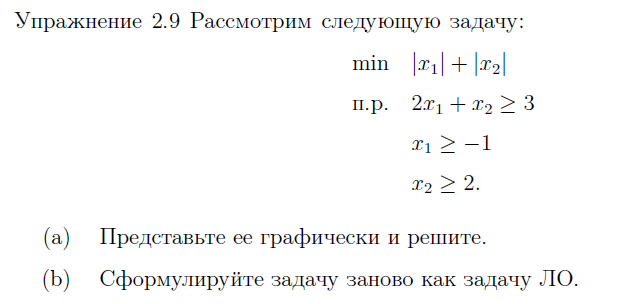

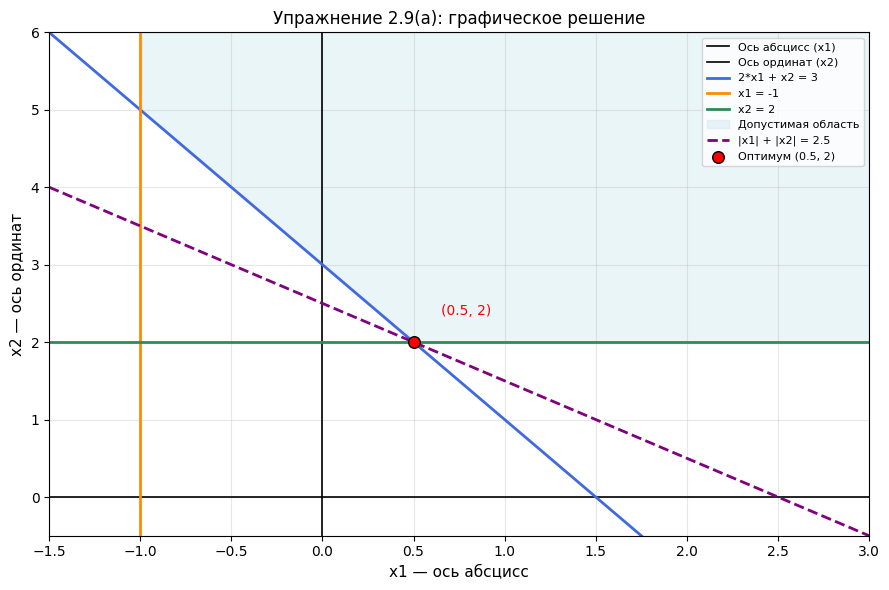

Решение задачи 2.9(a):
x1* = 0.5
x2* = 2
Минимум |x1| + |x2| = 2.5


In [17]:
import numpy as np
import matplotlib.pyplot as plt

# Создаём значения x1 для построения линий на графике.
x1_values = np.linspace(-1.5, 3, 400)

# Граница ограничения 2*x1 + x2 >= 3:
# на границе 2*x1 + x2 = 3, следовательно x2 = 3 - 2*x1.
x2_from_first_constraint = 3 - 2 * x1_values

# Второе нижнее ограничение: x2 >= 2.
x2_minimum = np.full_like(x1_values, 2.0)

# Допустимая область должна быть выше обеих нижних границ.
lower_boundary = np.maximum(x2_from_first_constraint, x2_minimum)

plt.figure(figsize=(9, 6))

# Оси координат рисуем чёрным цветом, чтобы отличались от линий ограничений.
plt.axhline(y=0, color="black", linewidth=1.2, label="Ось абсцисс (x1)")
plt.axvline(x=0, color="black", linewidth=1.2, label="Ось ординат (x2)")

# Прямые ограничений рисуем цветами, отличными от осей.
plt.plot(x1_values, x2_from_first_constraint, color="royalblue",
         linewidth=2, label="2*x1 + x2 = 3")
plt.axvline(x=-1, color="darkorange", linewidth=2, label="x1 = -1")
plt.axhline(y=2, color="seagreen", linewidth=2, label="x2 = 2")

# Допустимая область лежит выше обеих наклонной/горизонтальной границ и справа от x1=-1.
plt.fill_between(
    x1_values, lower_boundary, 6,
    where=(x1_values >= -1) & (lower_boundary <= 6),
    color="lightblue", alpha=0.25,
    label="Допустимая область"
)

# Линия уровня функции проходит через оптимальную точку (0.5, 2).
plt.plot(x1_values, 2.5 - x1_values, color="purple", linestyle="--",
         linewidth=2, label="|x1| + |x2| = 2.5")

# Оптимальная точка и подпись.
plt.scatter([0.5], [2], color="red", edgecolor="black", s=70,
            zorder=6, label="Оптимум (0.5, 2)")
plt.annotate("(0.5, 2)", (0.5, 2), xytext=(0.65, 2.35), color="red")

# Явно показываем x1 и x2 как названия осей, а не только координатные числа.
plt.xlabel("x1 — ось абсцисс", fontsize=11)
plt.ylabel("x2 — ось ординат", fontsize=11)
plt.xlim(-1.5, 3)
plt.ylim(-0.5, 6)
plt.title("Упражнение 2.9(a): графическое решение")
plt.grid(True, alpha=0.3)
plt.legend(loc="upper right", fontsize=8)
plt.tight_layout()
plt.show()


# Аналитическое решение задачи (пункт a):
x1_opt, x2_opt = 0.5, 2.0
objective_opt = abs(x1_opt) + abs(x2_opt)
print("Решение задачи 2.9(a):")
print(f"x1* = {x1_opt:g}")
print(f"x2* = {x2_opt:g}")
print(f"Минимум |x1| + |x2| = {objective_opt:g}")

In [18]:
# Пункт (b): исходная задача — задача ЛО
# Модули |x1| и |x2| заменены вспомогательными переменными t1 и t2.
m29 = pyo.ConcreteModel()

# Исходные x1 и x2 могут быть как отрицательными, так и положительными.
m29.x1 = pyo.Var(domain=pyo.Reals)
m29.x2 = pyo.Var(domain=pyo.Reals)

# t1 и t2 неотрицательны и будут равны модулям x1 и x2 в оптимуме.
m29.t1 = pyo.Var(domain=pyo.NonNegativeReals)
m29.t2 = pyo.Var(domain=pyo.NonNegativeReals)

# Минимизируем сумму вспомогательных переменных.
m29.objective = pyo.Objective(expr=m29.t1 + m29.t2, sense=pyo.minimize)

# Ограничения исходной задачи.
m29.main_constraint = pyo.Constraint(expr=2*m29.x1 + m29.x2 >= 3)
m29.x1_lower = pyo.Constraint(expr=m29.x1 >= -1)
m29.x2_lower = pyo.Constraint(expr=m29.x2 >= 2)

# Линеаризация модулей:
# t1 >= x1 и t1 >= -x1 означают t1 >= |x1|.
# Аналогично t2 >= x2 и t2 >= -x2 означают t2 >= |x2|.
m29.abs1_pos = pyo.Constraint(expr=m29.t1 >= m29.x1)
m29.abs1_neg = pyo.Constraint(expr=m29.t1 >= -m29.x1)
m29.abs2_pos = pyo.Constraint(expr=m29.t2 >= m29.x2)
m29.abs2_neg = pyo.Constraint(expr=m29.t2 >= -m29.x2)

# Передаём модель решателю и выводим оптимальное решение.
solve_model(m29, "2.9(b)")
print("Оптимальное x1 =", pyo.value(m29.x1))
print("Оптимальное x2 =", pyo.value(m29.x2))
print("Минимум |x1| + |x2| =", pyo.value(m29.objective))

Результат для: 2.9(b)
Статус решателя: optimal
Оптимальное x1 = 0.5
Оптимальное x2 = 2.0
Минимум |x1| + |x2| = 2.5


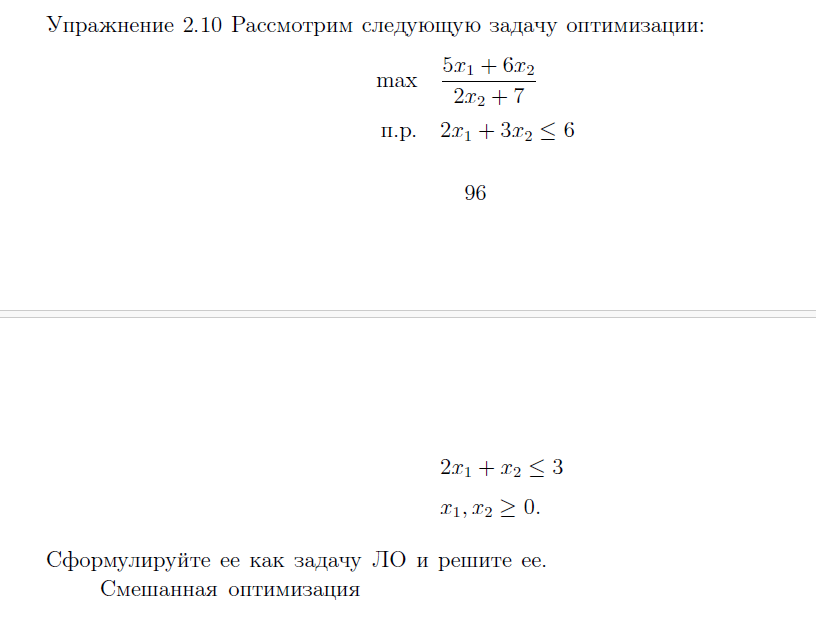

In [19]:
m210 = pyo.ConcreteModel()

# Новые переменные после преобразования Чарнса—Купера.
m210.y1 = pyo.Var(domain=pyo.NonNegativeReals)
m210.y2 = pyo.Var(domain=pyo.NonNegativeReals)
m210.t = pyo.Var(domain=pyo.NonNegativeReals)

# После замены дробная функция становится линейной.
m210.objective = pyo.Objective(expr=5*m210.y1 + 6*m210.y2, sense=pyo.maximize)

# Первое ограничение 2*x1 + 3*x2 <= 6 умножаем на t.
m210.constraint1 = pyo.Constraint(expr=2*m210.y1 + 3*m210.y2 <= 6*m210.t)

# Второе ограничение 2*x1 + x2 <= 3 также умножаем на t.
m210.constraint2 = pyo.Constraint(expr=2*m210.y1 + m210.y2 <= 3*m210.t)

# Условие, связывающее новые переменные со знаменателем.
m210.denominator = pyo.Constraint(expr=2*m210.y2 + 7*m210.t == 1)

solve_model(m210, "2.10, преобразованная линейная задача")

# Возвращаемся к исходным x1 и x2: x_i = y_i / t.
t_value = pyo.value(m210.t)
x1_value = pyo.value(m210.y1) / t_value
x2_value = pyo.value(m210.y2) / t_value

print("Исходная переменная x1 =", x1_value)
print("Исходная переменная x2 =", x2_value)
print("Максимальное значение дробной функции =", pyo.value(m210.objective))
print("Проверка исходной функции =", (5*x1_value + 6*x2_value)/(2*x2_value + 7))


Результат для: 2.10, преобразованная линейная задача
Статус решателя: optimal
Исходная переменная x1 = 0.7500000000000009
Исходная переменная x2 = 1.4999999999999996
Максимальное значение дробной функции = 1.2750000000000004
Проверка исходной функции = 1.275
